In [2]:
""" Phase 1: Data Exploration, Missing Values & Scaling
1. Data Exploration & Handling Missing Values  """
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('adult_with_headers (1).csv')

# Replace ' ?' (with leading space) or '?' with NaN
df = df.replace(' ?', np.nan).replace('?', np.nan)

# Check missing values
print("Missing values per column:\n", df.isnull().sum())

# Handle missing values: Impute categorical columns with the mode
for col in ['workclass', 'occupation', 'native_country']:
    df[col] = df[col].fillna(df[col].mode()[0])

Missing values per column:
 age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


In [4]:
# 2. Scaling Techniques (Standard Scaling vs. Min-Max Scaling) 
from sklearn.preprocessing import StandardScaler, MinMaxScaler

num_cols = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

# 1. Standard Scaling (Z-score normalization: mean=0, std=1)
standard_scaler = StandardScaler()
df_standard_scaled = df.copy()
df_standard_scaled[num_cols] = standard_scaler.fit_transform(df[num_cols])

# 2. Min-Max Scaling (Normalizes values between 0 and 1)
minmax_scaler = MinMaxScaler()
df_minmax_scaled = df.copy()
df_minmax_scaled[num_cols] = minmax_scaler.fit_transform(df[num_cols])

In [5]:
""" Discussion: When to prefer each scaling technique?Standard Scaling (Z-score): 
Preferred when features have different units and you are using models sensitive to feature magnitudes that 
assume a Gaussian distribution (e.g., Logistic Regression, SVMs, Principal Component Analysis (PCA), Neural Networks). 
It handles outliers better than Min-Max scaling because it doesn't squash all data into a tight range.Min-Max Scaling: 
Preferred when your algorithm requires bounded values in a specific range $[0, 1]$ (e.g., Neural Networks with activation functions like Sigmoid, 
or distance-based algorithms like K-Nearest Neighbors and K-Means clustering). However, it is highly sensitive to extreme outliers, which can 
compress the majority of normal data points into a very small interval."""


" Discussion: When to prefer each scaling technique?Standard Scaling (Z-score): \nPreferred when features have different units and you are using models sensitive to feature magnitudes that \nassume a Gaussian distribution (e.g., Logistic Regression, SVMs, Principal Component Analysis (PCA), Neural Networks). \nIt handles outliers better than Min-Max scaling because it doesn't squash all data into a tight range.Min-Max Scaling: \nPreferred when your algorithm requires bounded values in a specific range $[0, 1]$ (e.g., Neural Networks with activation functions like Sigmoid, \nor distance-based algorithms like K-Nearest Neighbors and K-Means clustering). However, it is highly sensitive to extreme outliers, which can \ncompress the majority of normal data points into a very small interval."

In [6]:
# Phase 2: Encoding Techniques
from sklearn.preprocessing import LabelEncoder

# Identify categorical columns
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols.remove('income') # Target variable

# Separate columns based on cardinality (< 5 vs >= 5)
low_card_cols = [col for col in cat_cols if df[col].nunique() < 5]
high_card_cols = [col for col in cat_cols if df[col].nunique() >= 5]

print("Low cardinality columns (< 5 categories):", low_card_cols)
print("High cardinality columns (>= 5 categories):", high_card_cols)

# 1. One-Hot Encoding for low cardinality columns
df_encoded = pd.get_dummies(df, columns=low_card_cols, drop_first=True, dtype=int)

# 2. Label Encoding for high cardinality columns
label_encoder = LabelEncoder()
for col in high_card_cols:
    df_encoded[col] = label_encoder.fit_transform(df_encoded[col])

# Encode target variable 'income'
df_encoded['income'] = df_encoded['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)

Low cardinality columns (< 5 categories): ['sex']
High cardinality columns (>= 5 categories): ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'native_country']


In [7]:
""" Discussion: Pros and Cons of One-Hot Encoding vs. Label EncodingOne-Hot Encoding:Pros: Prevents the model from assuming any ordinal relationship or false numerical hierarchy between categories.Cons: 
Leads to the curse of dimensionality when dealing with high-cardinality features (e.g., native_country with 41+ categories creates 41 new columns), causing high memory usage and sparsity.Label Encoding:Pros:
Keeps memory consumption low by mapping categories to integer values within a single column without adding extra dimensions.Cons: Imposes an artificial numeric ordering (e.g., $1 < 2 < 3$) which tree-based models 
can handle, but linear models or neural networks will incorrectly misinterpret as mathematical magnitude or rank. """


' Discussion: Pros and Cons of One-Hot Encoding vs. Label EncodingOne-Hot Encoding:Pros: Prevents the model from assuming any ordinal relationship or false numerical hierarchy between categories.Cons: \nLeads to the curse of dimensionality when dealing with high-cardinality features (e.g., native_country with 41+ categories creates 41 new columns), causing high memory usage and sparsity.Label Encoding:Pros:\nKeeps memory consumption low by mapping categories to integer values within a single column without adding extra dimensions.Cons: Imposes an artificial numeric ordering (e.g., $1 < 2 < 3$) which tree-based models \ncan handle, but linear models or neural networks will incorrectly misinterpret as mathematical magnitude or rank. '

In [8]:
# Phase 3: Feature Engineering & Transformation 
# Feature 1: Net Capital Gain
df['Net_Capital_Gain'] = df['capital_gain'] - df['capital_loss']

# Feature 2: Capital Earned per Working Hour
df['Capital_Per_Hour'] = df['capital_gain'] / (df['hours_per_week'] + 1)

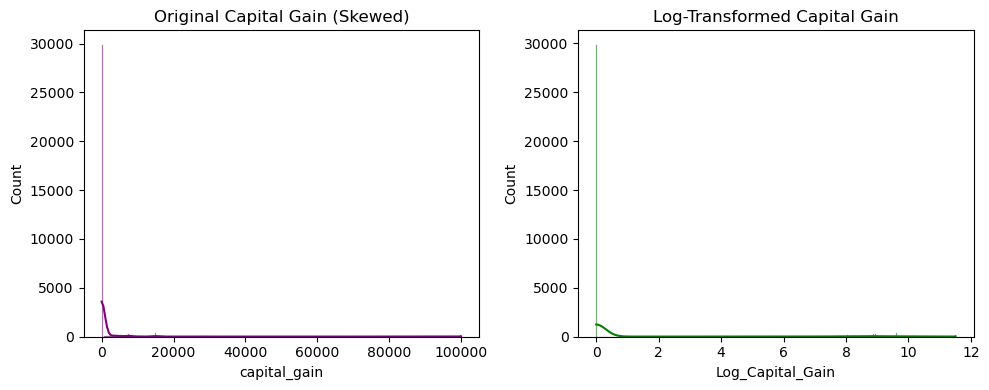

In [9]:
# 2. Skewed Feature Transformation
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Apply log transformation (log(1 + x) to handle zeros)
df['Log_Capital_Gain'] = np.log1p(df['capital_gain'])

# Visualization of transformation
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['capital_gain'], kde=True, color='purple')
plt.title('Original Capital Gain (Skewed)')

plt.subplot(1, 2, 2)
sns.histplot(df['Log_Capital_Gain'], kde=True, color='green')
plt.title('Log-Transformed Capital Gain')
plt.tight_layout()
plt.show()